# Declaración responsable sobre autoría y uso ético de inteligencia artificial, otros recursos o ayuda externa

Con la entrega de esta tarea, declaro de manera responsable que
es el resultado de mi trabajo intelectual personal y creativo, y que ha sido elaborado de acuerdo con los principios éticos y las normas de integridad vigentes en la comunidad académica y, más
específicamente, en la [Universidad Complutense de Madrid](https://www.ucm.es/file/declaracion-responsable-sobre-autoria-y-uso-%C3%89tico-de-herramientas-de-ia).

Soy, pues, autor del material aquí incluido y, cuando no ha sido así y he tomado el material de
otra fuente, lo he citado o bien he declarado su procedencia de forma clara -incluidas, en su
caso, herramientas de inteligencia artificial-. Las ideas y aportaciones principales incluidas en este trabajo, y que acreditan la adquisición de competencias, son mías y no proceden de otras fuentes o han sido reescritas usando material de otras fuentes.

Antes de entregar esta tarea, asegúrate de que todo funcione como se espera:

1. Reinicia el kernel  
   *(En la barra de menú, selecciona **Kernel → Restart**)*  

2. Ejecuta todas las celdas  
   *(En la barra de menú, selecciona **Cell → Run All**)*  

3. Asegúrate de completar todos los lugares donde aparezca:  
   - `YOUR CODE HERE`  
   - `"YOUR ANSWER HERE"`
     
4. Debes borrar las instrucciones que pone `raise NotImplementedError()`

5. Así como tu **nombre** a continuación:

In [1]:
NOMBRE = "JAIME RUIZ LÓPEZ-ALVARADO"

## Notas para la entrega

* Se deben rellenar todos los cuadernos sin cambiar el nombre.
* Es impor
* Se debe comprimir la carpeta `tarea_final` en un fichero `.zip`, llamado `tarea_final.zip`.
  
  **Importante**: por favor, no se entreguen ficheros `.rar`.

* Los ficheros CSV son bastante grandes y no son necesario incluirlos. Por eso es **importante** boorrarlos andes de generar el fichero comprimido.
* También es importante borrar los ficheros auxiliares como `*.ipynb_checkpoints`, `.mypy_cache`, `__pycache` y otros fiche.
* Subir el fichero comprimido al campus virtual.

# Ejercicio de Programación en Python: Los Mismos Análisis, con NumPy

Este cuaderno reutiliza la función `load_fines_data` de `E1_analisis_fichero.ipynb` y repite los mismos análisis de aquel cuaderno (recuento por calificación, importe total y medio, recuento por denunciante, lugar con más multas, histograma por hora con importe, y mínimo exceso de velocidad), pero esta vez con `numpy`: convertimos los datos en un array de `numpy` y resolvemos cada ejercicio de forma vectorizada, **sin usar bucles `for`/`while` explícitos**.

---

## Celda de Configuración: Importación de Módulos

### Reutilizar código de otro cuaderno con el paquete `ipynb`

Para no repetir `load_fines_data`, la importamos directamente desde `E1_analisis_fichero.ipynb` usando el paquete [`ipynb`](https://github.com/ipython/ipynb), que permite tratar un notebook como si fuera un módulo Python.

Usamos concretamente `ipynb.fs.defs` (no `ipynb.fs.full`): `fs.defs` importa **solo** las definiciones del notebook (funciones, clases, imports y constantes en mayúsculas) sin ejecutar el resto del código (los `print`, las comprobaciones y los tests de `E1`); `fs.full`, en cambio, ejecutaría el notebook entero de arriba a abajo cada vez que lo importáramos, lo cual sería lento e innecesario aquí.

Como `E1_analisis_fichero` es un nombre de módulo válido (empieza por una letra), basta con `import ipynb` seguido de `from ipynb.fs.defs.E1_analisis_fichero import load_fines_data, TrafficFine`, igual que harías con cualquier otro módulo.

Importa en la siguiente celda `numpy`, `doctest`, el módulo `testing`, y `load_fines_data` (y `TrafficFine`) desde `E1_analisis_fichero.ipynb` tal y como se explica arriba. En este ejercicio analizaremos el mismo fichero `2023_nov.csv` del que vemos las 10 primeras líneas.

In [2]:
with open('2023_nov.csv') as f:
    for _ in range(10):
        line = next(f).strip()
        print(line)

CALIFICACION;LUGAR;MES;ANIO;HORA;IMP_BOL;DESCUENTO; PUNTOS;DENUNCIANTE;HECHO-BOL;VEL_LIMITE;VEL_CIRCULA ;COORDENADA-X;COORDENADA-Y
LEVE      ;BRAVO MURILLO, 261                      ;11;2023;09.50;  60.00;SI;0;AGENTES DE MOVILIDAD          ;NO ADVERTIR LA MANIOBRAAL RESTO DE USUARIOS DE LA VÍA.                                                                       ;   ;   ;    4400.56;   44787.09
GRAVE     ;PEDRO RICO, 1                           ;11;2023;08.38; 200.00;SI;0;AGENTES DE MOVILIDAD          ;ESTACIONAR EN ZONA SEÑALIZADA PARA USO EXCLUSIVO DE PERSONAS CON MOVILIDAD REDUCIDA.                                         ;   ;   ;    4416.15;   44816.22
GRAVE     ;VELAZQUEZ, 80                           ;11;2023;11.33; 200.00;SI;3;AGENTES DE MOVILIDAD          ;CONDUCIR UTILIZANDO AURICULAR O DISPOSITIVO QUE DISMINUYA LA ATENCIÓN PERMANENTE A LA CONDUCCIÓN.                            ;   ;   ;    4419.77;   44753.77
LEVE      ;GERARDO CORDON, 53                      ;11;2023;11.27

Los tests de este cuaderno también están en el fichero `testing.py`, junto a los de los cuadernos anteriores.

In [3]:
import subprocess
import sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'ipynb', 'pytest'])

Defaulting to user installation because normal site-packages is not writeable


0

In [6]:
import pytest
import doctest
import os
import testing_02 as testing

# Tus import aquí
import numpy as np
import ipynb
from ipynb.fs.defs.E1_analisis_fichero import load_fines_data, TrafficFine

TESTDATAFILE = 'data_test.csv'
NOV_2023 = '2023_nov.csv' 

A partir de aquí reutilizamos `DATA`, la lista de `TrafficFine` cargada con la función que acabamos de importar, en el Ejercicio 1.

In [7]:
DATA = load_fines_data(2023, 'nov', TESTDATAFILE)
len(DATA)

2121

## Ejercicio 1: De Lista a Array de NumPy

Escribe una función con la cabecera `def records_to_array(data: list) -> np.ndarray:` que reciba la lista de `TrafficFine` (tal y como la devuelve `load_fines_data`) y la transforme en un **array estructurado de `numpy`** con los campos `'qualification'`, `'location'`, `'amount'`, `'complainant'`, `'hour'` (la hora, extraída de `date_time`), `'speed_limit'` y `'real_speed'`. Recuerda que `parse_row`/`load_fines_data` (en `E1_analisis_fichero.ipynb`) ya se encargan de dejar los campos de texto sin espacios sobrantes, así que aquí no hace falta volver a hacer `strip()`. Como `speed_limit` y `real_speed` pueden ser `None`, guárdalos como `float`, usando `np.nan` cuando el valor original sea `None` (los campos numéricos de un array de `numpy` no admiten `None`).

**Restricción:** no se permite ningún bucle `for`/`while` explícito para recorrer `data` (usa una comprensión de listas, tal y como hicimos en `E1_analisis_fichero.ipynb`); el resultado debe construirse con `np.array` y un `dtype` estructurado.

In [20]:
def records_to_array(data: list) -> np.ndarray:
    """Convierte una lista de TrafficFine en un array estructurado de numpy.

    Cada multa se convierte en una tupla con los campos de FINE_DTYPE. La
    hora se extrae de `date_time` y las velocidades se guardan como float,
    con np.nan cuando el valor original es None (los campos numéricos de
    numpy no admiten None).

    Args:
        data: Lista de TrafficFine, tal como la devuelve load_fines_data.

    Returns:
        np.ndarray: Array estructurado con los campos 'qualification',
        'location', 'amount', 'complainant', 'hour', 'speed_limit' y
        'real_speed'.

    Examples:
        >>> from datetime import datetime
        >>> data = [{'date_time': datetime(2023, 11, 1, 17, 37),
        ...          'qualification': 'GRAVE', 'location': 'CALLE MAYOR',
        ...          'amount': 200, 'complainant': 'SER',
        ...          'speed_limit': None, 'real_speed': None},
        ...         {'date_time': datetime(2023, 11, 1, 2, 42),
        ...          'qualification': 'GRAVE', 'location': 'M-30',
        ...          'amount': 100, 'complainant': 'POLICIA MUNICIPAL',
        ...          'speed_limit': 70, 'real_speed': 88}]
        >>> arr = records_to_array(data)
        >>> arr.shape
        (2,)
        >>> arr['hour'].tolist()
        [17, 2]
        >>> arr['amount'].tolist()
        [200, 100]
        >>> arr['speed_limit'].tolist()
        [nan, 70.0]
        >>> str(arr['qualification'][0]), str(arr['location'][1])
        ('GRAVE', 'M-30')
        >>> len(records_to_array([]))
        0
    """
    return np.array(
        [
            (
                fine['qualification'],
                fine['location'],
                fine['amount'],
                fine['complainant'],
                fine['date_time'].hour,
                np.nan if fine['speed_limit'] is None else fine['speed_limit'],
                np.nan if fine['real_speed'] is None else fine['real_speed'],
            )
            for fine in data
        ],
        dtype=np.dtype([
        ('qualification', 'U10'),
        ('location', 'U50'),
        ('amount', 'i8'),
        ('complainant', 'U40'),
        ('hour', 'i8'),
        ('speed_limit', 'f8'),
        ('real_speed', 'f8'),
    ]),
    )


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar la forma y los campos del array construido a partir de `DATA`.

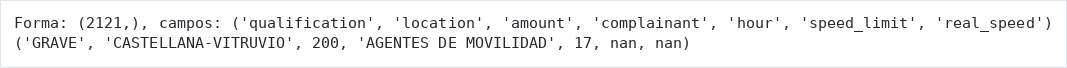

In [21]:
def check_records_to_array_result():
    arr = records_to_array(DATA)
    print(f'Forma: {arr.shape}, campos: {arr.dtype.names}')
    print(arr[0])
check_records_to_array_result()

Forma: (2121,), campos: ('qualification', 'location', 'amount', 'complainant', 'hour', 'speed_limit', 'real_speed')
('GRAVE', 'CASTELLANA-VITRUVIO', 200, 'AGENTES DE MOVILIDAD', 17, nan, nan)


Comprueba tus doctests

In [22]:
doctest.run_docstring_examples(records_to_array, globals(), verbose=True)

Finding tests in NoName
Trying:
    from datetime import datetime
Expecting nothing
ok
Trying:
    data = [{'date_time': datetime(2023, 11, 1, 17, 37),
             'qualification': 'GRAVE', 'location': 'CALLE MAYOR',
             'amount': 200, 'complainant': 'SER',
             'speed_limit': None, 'real_speed': None},
            {'date_time': datetime(2023, 11, 1, 2, 42),
             'qualification': 'GRAVE', 'location': 'M-30',
             'amount': 100, 'complainant': 'POLICIA MUNICIPAL',
             'speed_limit': 70, 'real_speed': 88}]
Expecting nothing
ok
Trying:
    arr = records_to_array(data)
Expecting nothing
ok
Trying:
    arr.shape
Expecting:
    (2,)
ok
Trying:
    arr['hour'].tolist()
Expecting:
    [17, 2]
ok
Trying:
    arr['amount'].tolist()
Expecting:
    [200, 100]
ok
Trying:
    arr['speed_limit'].tolist()
Expecting:
    [nan, 70.0]
ok
Trying:
    str(arr['qualification'][0]), str(arr['location'][1])
Expecting:
    ('GRAVE', 'M-30')
ok
Trying:
    len(records_

Comprueba la calidad del docstring

In [23]:
help(records_to_array)

Help on function records_to_array in module __main__:

records_to_array(data: list) -> numpy.ndarray
    Convierte una lista de TrafficFine en un array estructurado de numpy.
    
    Cada multa se convierte en una tupla con los campos de FINE_DTYPE. La
    hora se extrae de `date_time` y las velocidades se guardan como float,
    con np.nan cuando el valor original es None (los campos numéricos de
    numpy no admiten None).
    
    Args:
        data: Lista de TrafficFine, tal como la devuelve load_fines_data.
    
    Returns:
        np.ndarray: Array estructurado con los campos 'qualification',
        'location', 'amount', 'complainant', 'hour', 'speed_limit' y
        'real_speed'.
    
    Examples:
        >>> from datetime import datetime
        >>> data = [{'date_time': datetime(2023, 11, 1, 17, 37),
        ...          'qualification': 'GRAVE', 'location': 'CALLE MAYOR',
        ...          'amount': 200, 'complainant': 'SER',
        ...          'speed_limit': None, '

### Comprobación automática del código

In [24]:
testing.test_records_to_array(records_to_array, DATA)

test_records_to_array OK


In [25]:
testing.test_records_to_array_typehints(records_to_array)

check type hints OK


In [26]:
testing.test_docstring(records_to_array)

docstring OK


In [27]:
testing.test_doctests(records_to_array, globals())

doctests OK


A partir de aquí reutilizamos `ARR`, calculado con la función que acabas de implementar, en el resto de ejercicios del cuaderno.

In [28]:
ARR = records_to_array(DATA)
ARR.shape

(2121,)

## Ejercicio 2: Filtrado por Calificación con NumPy

Escribe una función con la cabecera `def count_by_qualification_np(arr: np.ndarray, qualification: str) -> int:` que reciba el array de multas y devuelva el número de multas que coinciden con una calificación (comparación insensible a mayúsculas/minúsculas).

**Restricción:** usa comparación vectorizada de `numpy` (`arr['qualification'] == ...` combinado con `np.sum`), sin ningún bucle explícito.

In [29]:
def count_by_qualification_np(arr: np.ndarray, qualification: str) -> int:
    """Cuenta las multas de una calificación con una comparación vectorizada.

    La comparación no distingue mayúsculas de minúsculas: se pasan a
    mayúsculas tanto la columna 'qualification' como el parámetro.

    Args:
        arr: Array estructurado de multas (ver records_to_array).
        qualification: Calificación a contar ('LEVE', 'GRAVE', 'MUY GRAVE').

    Returns:
        int: Número de multas con esa calificación.

    Examples:
        >>> arr = np.array([('GRAVE',), ('leve',), ('Grave',), ('MUY GRAVE',)],
        ...                dtype=[('qualification', 'U10')])
        >>> count_by_qualification_np(arr, 'GRAVE')
        2
        >>> count_by_qualification_np(arr, 'leve')
        1
        >>> count_by_qualification_np(arr, 'muy grave')
        1
        >>> count_by_qualification_np(arr, 'OTRA')
        0
    """
    matches = np.char.upper(arr['qualification']) == qualification.strip().upper()
    return int(np.sum(matches))


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar el número de multas GRAVE, LEVE y MUY GRAVE en `ARR`.

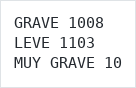

In [30]:
def check_count_by_qualification_np_result():
    for q in ('GRAVE', 'LEVE', 'MUY GRAVE'):
        print(q, count_by_qualification_np(ARR, q))
check_count_by_qualification_np_result()

GRAVE 1008
LEVE 1103
MUY GRAVE 10


Comprueba tus doctests

In [31]:
doctest.run_docstring_examples(count_by_qualification_np, globals(), verbose=True)

Finding tests in NoName
Trying:
    arr = np.array([('GRAVE',), ('leve',), ('Grave',), ('MUY GRAVE',)],
                   dtype=[('qualification', 'U10')])
Expecting nothing
ok
Trying:
    count_by_qualification_np(arr, 'GRAVE')
Expecting:
    2
ok
Trying:
    count_by_qualification_np(arr, 'leve')
Expecting:
    1
ok
Trying:
    count_by_qualification_np(arr, 'muy grave')
Expecting:
    1
ok
Trying:
    count_by_qualification_np(arr, 'OTRA')
Expecting:
    0
ok


Comprueba la calidad del docstring

In [32]:
help(count_by_qualification_np)

Help on function count_by_qualification_np in module __main__:

count_by_qualification_np(arr: numpy.ndarray, qualification: str) -> int
    Cuenta las multas de una calificación con una comparación vectorizada.
    
    La comparación no distingue mayúsculas de minúsculas: se pasan a
    mayúsculas tanto la columna 'qualification' como el parámetro.
    
    Args:
        arr: Array estructurado de multas (ver records_to_array).
        qualification: Calificación a contar ('LEVE', 'GRAVE', 'MUY GRAVE').
    
    Returns:
        int: Número de multas con esa calificación.
    
    Examples:
        >>> arr = np.array([('GRAVE',), ('leve',), ('Grave',), ('MUY GRAVE',)],
        ...                dtype=[('qualification', 'U10')])
        >>> count_by_qualification_np(arr, 'GRAVE')
        2
        >>> count_by_qualification_np(arr, 'leve')
        1
        >>> count_by_qualification_np(arr, 'muy grave')
        1
        >>> count_by_qualification_np(arr, 'OTRA')
        0



### Comprobación automática del código

In [33]:
testing.test_count_by_qualification_np(count_by_qualification_np, ARR)

test_count_by_qualification_np OK


In [34]:
testing.test_count_by_qualification_np_typehints(count_by_qualification_np)

check type hints OK


In [35]:
testing.test_docstring(count_by_qualification_np)

docstring OK


In [36]:
testing.test_doctests(count_by_qualification_np, globals())

doctests OK


## Ejercicio 3: Importe Total y Medio con NumPy

Escribe una función con la cabecera `def amount_stats_np(arr: np.ndarray) -> tuple[float, float]:` que reciba el array de multas y devuelva una tupla `(importe_total, importe_medio)`, redondeada a dos decimales, usando `np.sum` y `np.mean` sobre el campo `'amount'`.

In [37]:
# YOUR CODE HERE
def amount_stats_np(arr: np.ndarray) -> tuple[float, float]:
    """Calcula el importe total y el importe medio de las multas con numpy.

    Usa np.sum y np.mean sobre el campo 'amount' y redondea ambos valores
    a dos decimales. Si el array está vacío, devuelve (0.0, 0.0) en lugar
    de la media NaN que daría np.mean.

    Args:
        arr: Array estructurado de multas con el campo 'amount'.

    Returns:
        tuple[float, float]: (importe total, importe medio).

    Examples:
        >>> arr = np.array([(200,), (90,), (60,)], dtype=[('amount', 'i8')])
        >>> amount_stats_np(arr)
        (350.0, 116.67)
        >>> amount_stats_np(np.array([(100,), (50,)], dtype=[('amount', 'i8')]))
        (150.0, 75.0)
        >>> amount_stats_np(np.array([], dtype=[('amount', 'i8')]))
        (0.0, 0.0)
    """
    if arr.size == 0:
        return 0.0, 0.0
    total = round(float(np.sum(arr['amount'])), 2)
    average = round(float(np.mean(arr['amount'])), 2)
    return total, average


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar el importe total y medio de `ARR`.

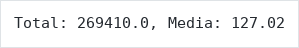

In [38]:
def check_amount_stats_np_result():
    total, average = amount_stats_np(ARR)
    print(f'Total: {total}, Media: {average}')
check_amount_stats_np_result()

Total: 269410.0, Media: 127.02


Comprueba tus doctests

In [39]:
doctest.run_docstring_examples(amount_stats_np, globals(), verbose=True)

Finding tests in NoName
Trying:
    arr = np.array([(200,), (90,), (60,)], dtype=[('amount', 'i8')])
Expecting nothing
ok
Trying:
    amount_stats_np(arr)
Expecting:
    (350.0, 116.67)
ok
Trying:
    amount_stats_np(np.array([(100,), (50,)], dtype=[('amount', 'i8')]))
Expecting:
    (150.0, 75.0)
ok
Trying:
    amount_stats_np(np.array([], dtype=[('amount', 'i8')]))
Expecting:
    (0.0, 0.0)
ok


Comprueba la calidad del docstring

In [40]:
help(amount_stats_np)

Help on function amount_stats_np in module __main__:

amount_stats_np(arr: numpy.ndarray) -> tuple[float, float]
    Calcula el importe total y el importe medio de las multas con numpy.
    
    Usa np.sum y np.mean sobre el campo 'amount' y redondea ambos valores
    a dos decimales. Si el array está vacío, devuelve (0.0, 0.0) en lugar
    de la media NaN que daría np.mean.
    
    Args:
        arr: Array estructurado de multas con el campo 'amount'.
    
    Returns:
        tuple[float, float]: (importe total, importe medio).
    
    Examples:
        >>> arr = np.array([(200,), (90,), (60,)], dtype=[('amount', 'i8')])
        >>> amount_stats_np(arr)
        (350.0, 116.67)
        >>> amount_stats_np(np.array([(100,), (50,)], dtype=[('amount', 'i8')]))
        (150.0, 75.0)
        >>> amount_stats_np(np.array([], dtype=[('amount', 'i8')]))
        (0.0, 0.0)



### Comprobación automática del código

In [41]:
testing.test_amount_stats_np(amount_stats_np, ARR)

test_amount_stats_np OK


In [42]:
testing.test_amount_stats_np_typehints(amount_stats_np)

check type hints OK


In [43]:
testing.test_docstring(amount_stats_np)

docstring OK


In [44]:
testing.test_doctests(amount_stats_np, globals())

doctests OK


## Ejercicio 4: Agregación por Denunciante con NumPy

Escribe una función con la cabecera `def count_by_complainant_np(arr: np.ndarray) -> dict:` que reciba el array de multas y devuelva un diccionario `denunciante -> número de multas`.

**Restricción:** usa `np.unique(arr['complainant'], return_counts=True)`; no se permite ningún bucle sobre las multas (miles de elementos).

In [45]:
def count_by_complainant_np(arr: np.ndarray) -> dict:
    """Cuenta las multas de cada denunciante con np.unique.

    np.unique devuelve los denunciantes distintos (ordenados
    alfabéticamente) y, con return_counts=True, cuántas veces aparece
    cada uno. Con zip se emparejan y se construye el diccionario.

    Args:
        arr: Array estructurado de multas con el campo 'complainant'.

    Returns:
        dict: Diccionario denunciante -> número de multas. Vacío si el
        array no tiene multas.

    Examples:
        >>> arr = np.array([('SER',), ('POLICIA MUNICIPAL',), ('SER',)],
        ...                dtype=[('complainant', 'U40')])
        >>> count_by_complainant_np(arr)
        {'POLICIA MUNICIPAL': 1, 'SER': 2}
        >>> count_by_complainant_np(np.array([], dtype=[('complainant', 'U40')]))
        {}
    """
    names, counts = np.unique(arr['complainant'], return_counts=True)
    return dict(zip(names.tolist(), counts.tolist()))


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar el recuento de multas por denunciante en `ARR`.

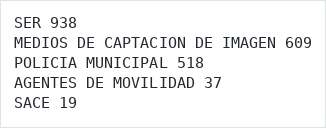

In [46]:
def check_count_by_complainant_np_result():
    result = count_by_complainant_np(ARR)
    for complainant, count in sorted(result.items(), key=lambda item: -item[1]):
        print(complainant, count)
check_count_by_complainant_np_result()

SER 938
MEDIOS DE CAPTACION DE IMAGEN 609
POLICIA MUNICIPAL 518
AGENTES DE MOVILIDAD 37
SACE 19


Comprueba tus doctests

In [47]:
doctest.run_docstring_examples(count_by_complainant_np, globals(), verbose=True)

Finding tests in NoName
Trying:
    arr = np.array([('SER',), ('POLICIA MUNICIPAL',), ('SER',)],
                   dtype=[('complainant', 'U40')])
Expecting nothing
ok
Trying:
    count_by_complainant_np(arr)
Expecting:
    {'POLICIA MUNICIPAL': 1, 'SER': 2}
ok
Trying:
    count_by_complainant_np(np.array([], dtype=[('complainant', 'U40')]))
Expecting:
    {}
ok


Comprueba la calidad del docstring

In [48]:
help(count_by_complainant_np)

Help on function count_by_complainant_np in module __main__:

count_by_complainant_np(arr: numpy.ndarray) -> dict
    Cuenta las multas de cada denunciante con np.unique.
    
    np.unique devuelve los denunciantes distintos (ordenados
    alfabéticamente) y, con return_counts=True, cuántas veces aparece
    cada uno. Con zip se emparejan y se construye el diccionario.
    
    Args:
        arr: Array estructurado de multas con el campo 'complainant'.
    
    Returns:
        dict: Diccionario denunciante -> número de multas. Vacío si el
        array no tiene multas.
    
    Examples:
        >>> arr = np.array([('SER',), ('POLICIA MUNICIPAL',), ('SER',)],
        ...                dtype=[('complainant', 'U40')])
        >>> count_by_complainant_np(arr)
        {'POLICIA MUNICIPAL': 1, 'SER': 2}
        >>> count_by_complainant_np(np.array([], dtype=[('complainant', 'U40')]))
        {}



### Comprobación automática del código

In [49]:
testing.test_count_by_complainant_np(count_by_complainant_np, ARR)

test_count_by_complainant_np OK


In [50]:
testing.test_count_by_complainant_np_typehints(count_by_complainant_np)

check type hints OK


In [51]:
testing.test_docstring(count_by_complainant_np)

docstring OK


In [52]:
testing.test_doctests(count_by_complainant_np, globals())

doctests OK


## Ejercicio 5: Lugar con Más Infracciones con NumPy

Escribe una función con la cabecera `def top_location_fines_np(arr: np.ndarray) -> tuple[str, int]:` que reciba el array de multas y devuelva una tupla `(lugar, número_de_multas)` con el lugar que tiene más multas.

**Restricción:** usa `np.unique(arr['location'], return_counts=True)` junto con `np.argmax`; sin bucles explícitos.

In [53]:
def top_location_fines_np(arr: np.ndarray) -> tuple[str, int]:
    """Devuelve el lugar con más multas y cuántas tiene, usando numpy.

    np.unique obtiene los lugares distintos y sus recuentos, y np.argmax
    la posición del recuento más alto. Si hay empate, se devuelve el lugar
    que va primero alfabéticamente (np.unique los ordena). Si el array
    está vacío, devuelve ('', 0).

    Args:
        arr: Array estructurado de multas con el campo 'location'.

    Returns:
        tuple[str, int]: (lugar con más multas, número de multas).

    Examples:
        >>> arr = np.array([('GRAN VIA, 46',), ('ALCALA, 1',), ('GRAN VIA, 46',)],
        ...                dtype=[('location', 'U50')])
        >>> top_location_fines_np(arr)
        ('GRAN VIA, 46', 2)
        >>> top_location_fines_np(np.array([('ALCALA, 1',)], dtype=[('location', 'U50')]))
        ('ALCALA, 1', 1)
        >>> top_location_fines_np(np.array([], dtype=[('location', 'U50')]))
        ('', 0)
    """
    if arr.size == 0:
        return '', 0
    locations, counts = np.unique(arr['location'], return_counts=True)
    top = np.argmax(counts)
    return str(locations[top]), int(counts[top])


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar el lugar con más multas en `ARR`.

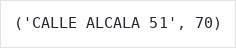

In [54]:
def check_top_location_fines_np_result():
    print(top_location_fines_np(ARR))
check_top_location_fines_np_result()

('CALLE ALCALA 51', 70)


Comprueba tus doctests

In [55]:
doctest.run_docstring_examples(top_location_fines_np, globals(), verbose=True)

Finding tests in NoName
Trying:
    arr = np.array([('GRAN VIA, 46',), ('ALCALA, 1',), ('GRAN VIA, 46',)],
                   dtype=[('location', 'U50')])
Expecting nothing
ok
Trying:
    top_location_fines_np(arr)
Expecting:
    ('GRAN VIA, 46', 2)
ok
Trying:
    top_location_fines_np(np.array([('ALCALA, 1',)], dtype=[('location', 'U50')]))
Expecting:
    ('ALCALA, 1', 1)
ok
Trying:
    top_location_fines_np(np.array([], dtype=[('location', 'U50')]))
Expecting:
    ('', 0)
ok


Comprueba la calidad del docstring

In [56]:
help(top_location_fines_np)

Help on function top_location_fines_np in module __main__:

top_location_fines_np(arr: numpy.ndarray) -> tuple[str, int]
    Devuelve el lugar con más multas y cuántas tiene, usando numpy.
    
    np.unique obtiene los lugares distintos y sus recuentos, y np.argmax
    la posición del recuento más alto. Si hay empate, se devuelve el lugar
    que va primero alfabéticamente (np.unique los ordena). Si el array
    está vacío, devuelve ('', 0).
    
    Args:
        arr: Array estructurado de multas con el campo 'location'.
    
    Returns:
        tuple[str, int]: (lugar con más multas, número de multas).
    
    Examples:
        >>> arr = np.array([('GRAN VIA, 46',), ('ALCALA, 1',), ('GRAN VIA, 46',)],
        ...                dtype=[('location', 'U50')])
        >>> top_location_fines_np(arr)
        ('GRAN VIA, 46', 2)
        >>> top_location_fines_np(np.array([('ALCALA, 1',)], dtype=[('location', 'U50')]))
        ('ALCALA, 1', 1)
        >>> top_location_fines_np(np.array([]

### Comprobación automática del código

In [57]:
testing.test_top_location_fines_np(top_location_fines_np, ARR)

test_top_location_fines_np OK


In [58]:
testing.test_top_location_fines_np_typehints(top_location_fines_np)

check type hints OK


In [59]:
testing.test_docstring(top_location_fines_np)

docstring OK


In [60]:
testing.test_doctests(top_location_fines_np, globals())

doctests OK


## Ejercicio 6: Datos por Hora con NumPy

Escribe una función con la cabecera `def fines_by_hour_np(arr: np.ndarray) -> np.ndarray:` que reciba el array de multas y devuelva un **array estructurado** de 24 elementos, con campos `'count'`, `'total'` y `'mean'`, análogo al `Counter` de `E1_analisis_fichero.ipynb`: el índice `h` contiene el número de multas, el importe total y el importe medio de la hora `h`.

**Restricción:** todo el cálculo debe ser vectorizado, sin ningún bucle explícito sobre las multas. Pista: `np.bincount` permite acumular tanto recuentos como sumas ponderadas (`weights=...`) en una sola pasada; usa `np.divide` con el parámetro `where` para calcular la media evitando la división por cero en las horas sin multas.

In [61]:
def fines_by_hour_np(arr: np.ndarray) -> np.ndarray:
    """Agrupa las multas por hora del día (0-23) de forma vectorizada.

    Devuelve un array estructurado de 24 elementos con los campos 'count',
    'total' y 'mean' (análogo al Counter de E1): el índice h contiene el
    número de multas, el importe total y el importe medio de la hora h.
    Las horas sin multas tienen count 0, total 0 y mean 0.0.

    Args:
        arr: Array estructurado de multas con los campos 'hour' y 'amount'.

    Returns:
        np.ndarray: Array estructurado de 24 elementos con HOUR_DTYPE.

    Examples:
        >>> arr = np.array([(13, 200), (13, 90), (8, 60)],
        ...                dtype=[('hour', 'i8'), ('amount', 'i8')])
        >>> result = fines_by_hour_np(arr)
        >>> len(result)
        24
        >>> result[13].tolist()
        (2, 290, 145.0)
        >>> result[8].tolist()
        (1, 60, 60.0)
        >>> result[0].tolist()
        (0, 0, 0.0)
        >>> empty = np.array([], dtype=[('hour', 'i8'), ('amount', 'i8')])
        >>> int(fines_by_hour_np(empty)['count'].sum())
        0
    """
    hours = arr['hour'].astype(np.int64)
    counts = np.bincount(hours, minlength=24)
    totals = np.bincount(hours, weights=arr['amount'], minlength=24)
    means = np.divide(totals, counts, out=np.zeros(24), where=counts > 0)

    result = np.zeros(24, dtype=np.dtype([('count', 'i8'), ('total', 'i8'), ('mean', 'f8')]))
    result['count'] = counts
    result['total'] = totals
    result['mean'] = np.round(means, 2)
    return result


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar el histograma de multas por hora en `ARR`.

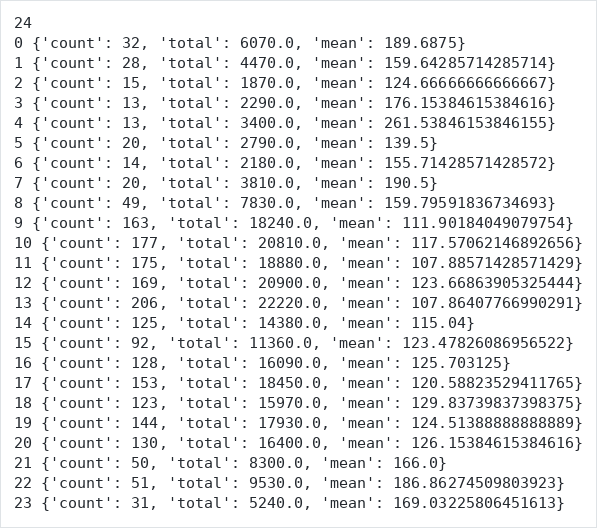

In [62]:
def check_fines_by_hour_np_result():
    result = fines_by_hour_np(ARR)
    print(len(result))
    for hour, row in enumerate(result):
        print(hour, dict(count=int(row['count']), total=float(row['total']), mean=float(row['mean'])))
check_fines_by_hour_np_result()

24
0 {'count': 32, 'total': 6070.0, 'mean': 189.69}
1 {'count': 28, 'total': 4470.0, 'mean': 159.64}
2 {'count': 15, 'total': 1870.0, 'mean': 124.67}
3 {'count': 13, 'total': 2290.0, 'mean': 176.15}
4 {'count': 13, 'total': 3400.0, 'mean': 261.54}
5 {'count': 20, 'total': 2790.0, 'mean': 139.5}
6 {'count': 14, 'total': 2180.0, 'mean': 155.71}
7 {'count': 20, 'total': 3810.0, 'mean': 190.5}
8 {'count': 49, 'total': 7830.0, 'mean': 159.8}
9 {'count': 163, 'total': 18240.0, 'mean': 111.9}
10 {'count': 177, 'total': 20810.0, 'mean': 117.57}
11 {'count': 175, 'total': 18880.0, 'mean': 107.89}
12 {'count': 169, 'total': 20900.0, 'mean': 123.67}
13 {'count': 206, 'total': 22220.0, 'mean': 107.86}
14 {'count': 125, 'total': 14380.0, 'mean': 115.04}
15 {'count': 92, 'total': 11360.0, 'mean': 123.48}
16 {'count': 128, 'total': 16090.0, 'mean': 125.7}
17 {'count': 153, 'total': 18450.0, 'mean': 120.59}
18 {'count': 123, 'total': 15970.0, 'mean': 129.84}
19 {'count': 144, 'total': 17930.0, 'mean':

Comprueba tus doctests

In [63]:
doctest.run_docstring_examples(fines_by_hour_np, globals(), verbose=True)

Finding tests in NoName
Trying:
    arr = np.array([(13, 200), (13, 90), (8, 60)],
                   dtype=[('hour', 'i8'), ('amount', 'i8')])
Expecting nothing
ok
Trying:
    result = fines_by_hour_np(arr)
Expecting nothing
ok
Trying:
    len(result)
Expecting:
    24
ok
Trying:
    result[13].tolist()
Expecting:
    (2, 290, 145.0)
ok
Trying:
    result[8].tolist()
Expecting:
    (1, 60, 60.0)
ok
Trying:
    result[0].tolist()
Expecting:
    (0, 0, 0.0)
ok
Trying:
    empty = np.array([], dtype=[('hour', 'i8'), ('amount', 'i8')])
Expecting nothing
ok
Trying:
    int(fines_by_hour_np(empty)['count'].sum())
Expecting:
    0
ok


Comprueba la calidad del docstring

In [64]:
help(fines_by_hour_np)

Help on function fines_by_hour_np in module __main__:

fines_by_hour_np(arr: numpy.ndarray) -> numpy.ndarray
    Agrupa las multas por hora del día (0-23) de forma vectorizada.
    
    Devuelve un array estructurado de 24 elementos con los campos 'count',
    'total' y 'mean' (análogo al Counter de E1): el índice h contiene el
    número de multas, el importe total y el importe medio de la hora h.
    Las horas sin multas tienen count 0, total 0 y mean 0.0.
    
    Args:
        arr: Array estructurado de multas con los campos 'hour' y 'amount'.
    
    Returns:
        np.ndarray: Array estructurado de 24 elementos con HOUR_DTYPE.
    
    Examples:
        >>> arr = np.array([(13, 200), (13, 90), (8, 60)],
        ...                dtype=[('hour', 'i8'), ('amount', 'i8')])
        >>> result = fines_by_hour_np(arr)
        >>> len(result)
        24
        >>> result[13].tolist()
        (2, 290, 145.0)
        >>> result[8].tolist()
        (1, 60, 60.0)
        >>> result[0].t

### Comprobación automática del código

In [65]:
testing.test_fines_by_hour_np(fines_by_hour_np, ARR)

test_fines_by_hour_np OK


In [66]:
testing.test_fines_by_hour_np_typehints(fines_by_hour_np)

check type hints OK


In [67]:
testing.test_docstring(fines_by_hour_np)

docstring OK


In [68]:
testing.test_doctests(fines_by_hour_np, globals())

doctests OK


## Ejercicio 7: Mínimo Exceso de Velocidad con NumPy

Escribe una función con la cabecera `def min_speed_excess_np(arr: np.ndarray) -> int:` que reciba el array de multas y devuelva el **mínimo** exceso de velocidad (`real_speed - speed_limit`) entre las multas que tienen ambos valores registrados. Si ninguna multa tiene ambos valores, debe devolver `0`.

**Restricción:** sin bucles ni indexado booleano explícito. Pista: al restar dos arrays de `numpy`, si un elemento de cualquiera de los dos operandos es `np.nan`, el resultado en esa posición también es `np.nan`; `np.nanmin` ignora automáticamente los `nan` al calcular el mínimo.

In [69]:
# YOUR CODE HERE
def min_speed_excess_np(arr: np.ndarray) -> int:
    """Devuelve el mínimo exceso de velocidad (real_speed - speed_limit).

    La resta se hace sobre las columnas completas: donde falta alguna de
    las dos velocidades (np.nan), el exceso también es np.nan, y
    np.nanmin lo ignora al calcular el mínimo. Si ninguna multa tiene
    ambos valores (o el array está vacío), devuelve 0.

    Args:
        arr: Array estructurado de multas con los campos 'speed_limit' y
            'real_speed' (float, con np.nan si falta el valor).

    Returns:
        int: Mínimo exceso de velocidad en km/h, o 0 si no hay multas de
        velocidad.

    Examples:
        >>> dt = [('speed_limit', 'f8'), ('real_speed', 'f8')]
        >>> arr = np.array([(70, 88), (50, 61), (np.nan, np.nan), (90, np.nan)], dtype=dt)
        >>> min_speed_excess_np(arr)
        11
        >>> min_speed_excess_np(np.array([(np.nan, np.nan)], dtype=dt))
        0
        >>> min_speed_excess_np(np.array([], dtype=dt))
        0
    """
    excess = arr['real_speed'] - arr['speed_limit']
    if np.all(np.isnan(excess)):
        return 0
    return int(np.nanmin(excess))


In [ ]:
# Escribe aquí tus pruebas



### Auto comprobación

La salida de la siguiente casilla debe mostrar el mínimo exceso de velocidad en `ARR`.

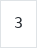

In [70]:
def check_min_speed_excess_np_result():
    print(min_speed_excess_np(ARR))
check_min_speed_excess_np_result()

3


Comprueba tus doctests

In [71]:
doctest.run_docstring_examples(min_speed_excess_np, globals(), verbose=True)

Finding tests in NoName
Trying:
    dt = [('speed_limit', 'f8'), ('real_speed', 'f8')]
Expecting nothing
ok
Trying:
    arr = np.array([(70, 88), (50, 61), (np.nan, np.nan), (90, np.nan)], dtype=dt)
Expecting nothing
ok
Trying:
    min_speed_excess_np(arr)
Expecting:
    11
ok
Trying:
    min_speed_excess_np(np.array([(np.nan, np.nan)], dtype=dt))
Expecting:
    0
ok
Trying:
    min_speed_excess_np(np.array([], dtype=dt))
Expecting:
    0
ok


Comprueba la calidad del docstring

In [72]:
help(min_speed_excess_np)

Help on function min_speed_excess_np in module __main__:

min_speed_excess_np(arr: numpy.ndarray) -> int
    Devuelve el mínimo exceso de velocidad (real_speed - speed_limit).
    
    La resta se hace sobre las columnas completas: donde falta alguna de
    las dos velocidades (np.nan), el exceso también es np.nan, y
    np.nanmin lo ignora al calcular el mínimo. Si ninguna multa tiene
    ambos valores (o el array está vacío), devuelve 0.
    
    Args:
        arr: Array estructurado de multas con los campos 'speed_limit' y
            'real_speed' (float, con np.nan si falta el valor).
    
    Returns:
        int: Mínimo exceso de velocidad en km/h, o 0 si no hay multas de
        velocidad.
    
    Examples:
        >>> dt = [('speed_limit', 'f8'), ('real_speed', 'f8')]
        >>> arr = np.array([(70, 88), (50, 61), (np.nan, np.nan), (90, np.nan)], dtype=dt)
        >>> min_speed_excess_np(arr)
        11
        >>> min_speed_excess_np(np.array([(np.nan, np.nan)], dtype=dt))
 

### Comprobación automática del código

In [73]:
testing.test_min_speed_excess_np(min_speed_excess_np, ARR)

test_min_speed_excess_np OK


In [74]:
testing.test_min_speed_excess_np_typehints(min_speed_excess_np)

check type hints OK


In [75]:
testing.test_docstring(min_speed_excess_np)

docstring OK


In [76]:
testing.test_doctests(min_speed_excess_np, globals())

doctests OK


## Comprobación final antes de entregar

**Guarda el cuaderno ahora (Ctrl+S / Cmd+S)** y, después, ejecuta la siguiente casilla. Comprueba que no haya identificadores de celda duplicados (algo que suele pasar al copiar una celda de solución o de test en vez de escribir en la tuya propia).

In [77]:
testing.check_duplicated_ids('E2_numpy.ipynb')

OK. No se han encontrado grade_id duplicados.
